# Lab Khai phá dữ liệu - Mushroom (Câu 6)
**Trần Minh Tấn - 6451071071**

## Cell 1: Cài đặt, kết nối dữ liệu và nhập dữ liệu

In [1]:
!pip install -q gdown

import gdown, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 55)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 55)

info("Nhập dữ liệu Mushroom")

FILE_ID = "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW"   # mushrooms.csv
gdown.download(id=FILE_ID, output="mushrooms.csv", quiet=False)

df = pd.read_csv("mushrooms.csv")
print("Kích thước dữ liệu:", df.shape)
print("Số ô dữ liệu trống:", df.isna().sum().sum())
print("\nPhân bố nhãn class (e = ăn được, p = nấm độc):")
print(df["class"].value_counts())
df.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Nhập dữ liệu Mushroom


Downloading...
From: https://drive.google.com/uc?id=11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW
To: /content/mushrooms.csv
100%|██████████| 374k/374k [00:00<00:00, 8.35MB/s]

Kích thước dữ liệu: (8124, 23)
Số ô dữ liệu trống: 0

Phân bố nhãn class (e = ăn được, p = nấm độc):
class
e    4208
p    3916
Name: count, dtype: int64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## Cell 2: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định

In [2]:
info("Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (class)")

X = df.drop(columns="class")   # thuộc tính bình thường
y = df["class"]                # thuộc tính quyết định

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (class)
Kích thước X: (8124, 22)
Kích thước y: (8124,)


## Cell 3: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector

In [3]:
info("Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector")

cat_cols = X.select_dtypes(exclude=np.number).columns
print("Số cột không phải dạng số:", len(cat_cols), "(toàn bộ thuộc tính)")

X = pd.get_dummies(X, columns=cat_cols, dtype=int)
print("Kích thước X sau one-hot:", X.shape)
X.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector
Số cột không phải dạng số: 22 (toàn bộ thuộc tính)
Kích thước X sau one-hot: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Cell 4: Câu 6 - Tách dữ liệu thành tập huấn luyện (70%) và kiểm thử (30%)

In [4]:
info("Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%
X_train: (5686, 117) | y_train: (5686,)
X_test : (2438, 117) | y_test : (2438,)


## Cell 5: Câu 7 - Cây ID3

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 7 - Cây ID3
Accuracy ID3: 1.0
Độ sâu cây: 5 | Số lá: 11
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



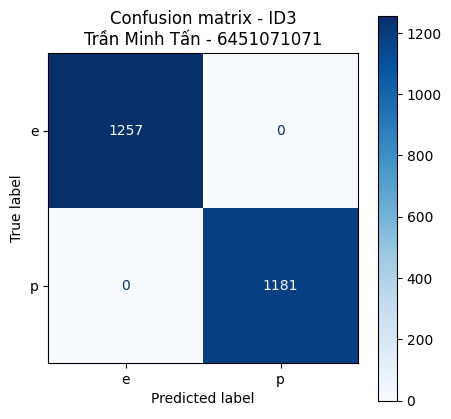

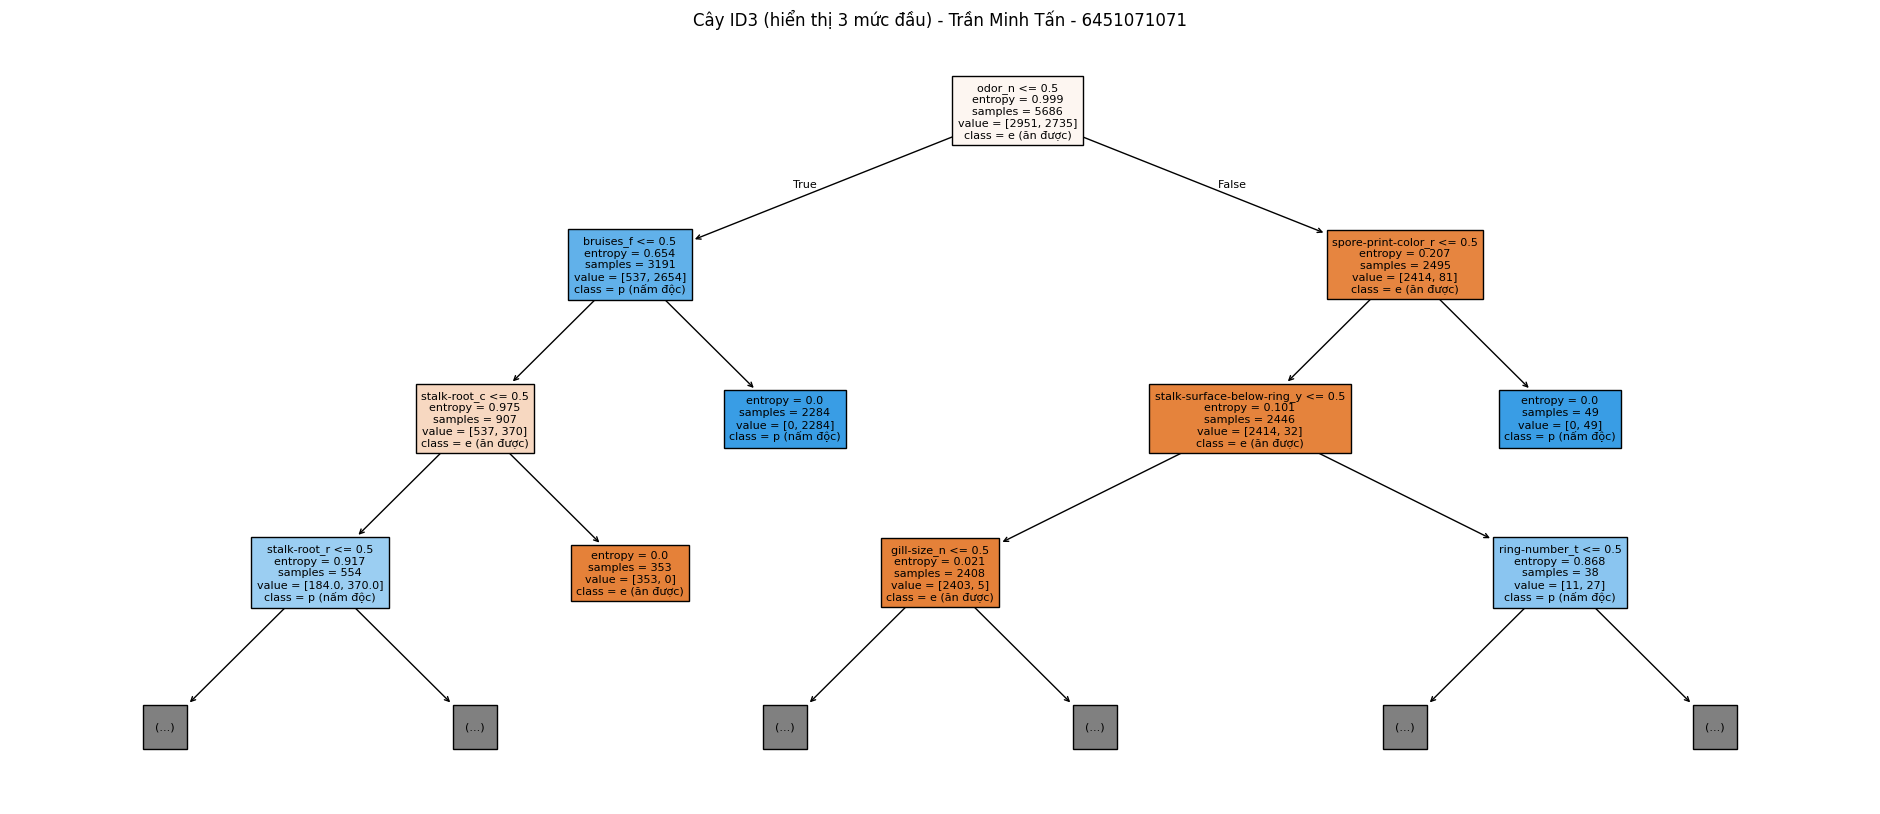

In [5]:
info("Câu 7 - Cây ID3")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)

# ID3 dùng entropy (information gain)
id3 = DecisionTreeClassifier(criterion="entropy", random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Accuracy ID3:", round(accuracy_score(y_test, pred_id3), 4))
print("Độ sâu cây:", id3.get_depth(), "| Số lá:", id3.get_n_leaves())
print(classification_report(y_test, pred_id3, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_id3, labels=["e","p"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - ID3\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(24,10))
plot_tree(id3, feature_names=X_train.columns, class_names=["e (ăn được)", "p (nấm độc)"],
          filled=True, fontsize=8, max_depth=3)
plt.title(f"Cây ID3 (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 6: Câu 8 - Cây CART

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 8 - Cây CART
Accuracy CART: 1.0
Độ sâu cây: 7 | Số lá: 14
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



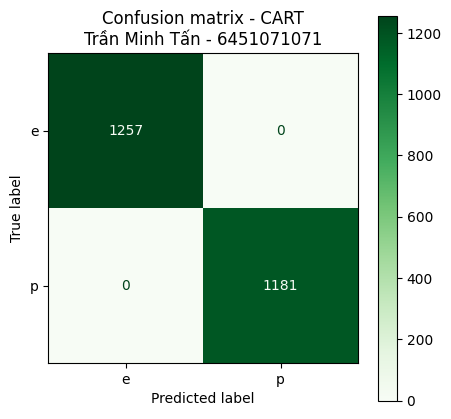

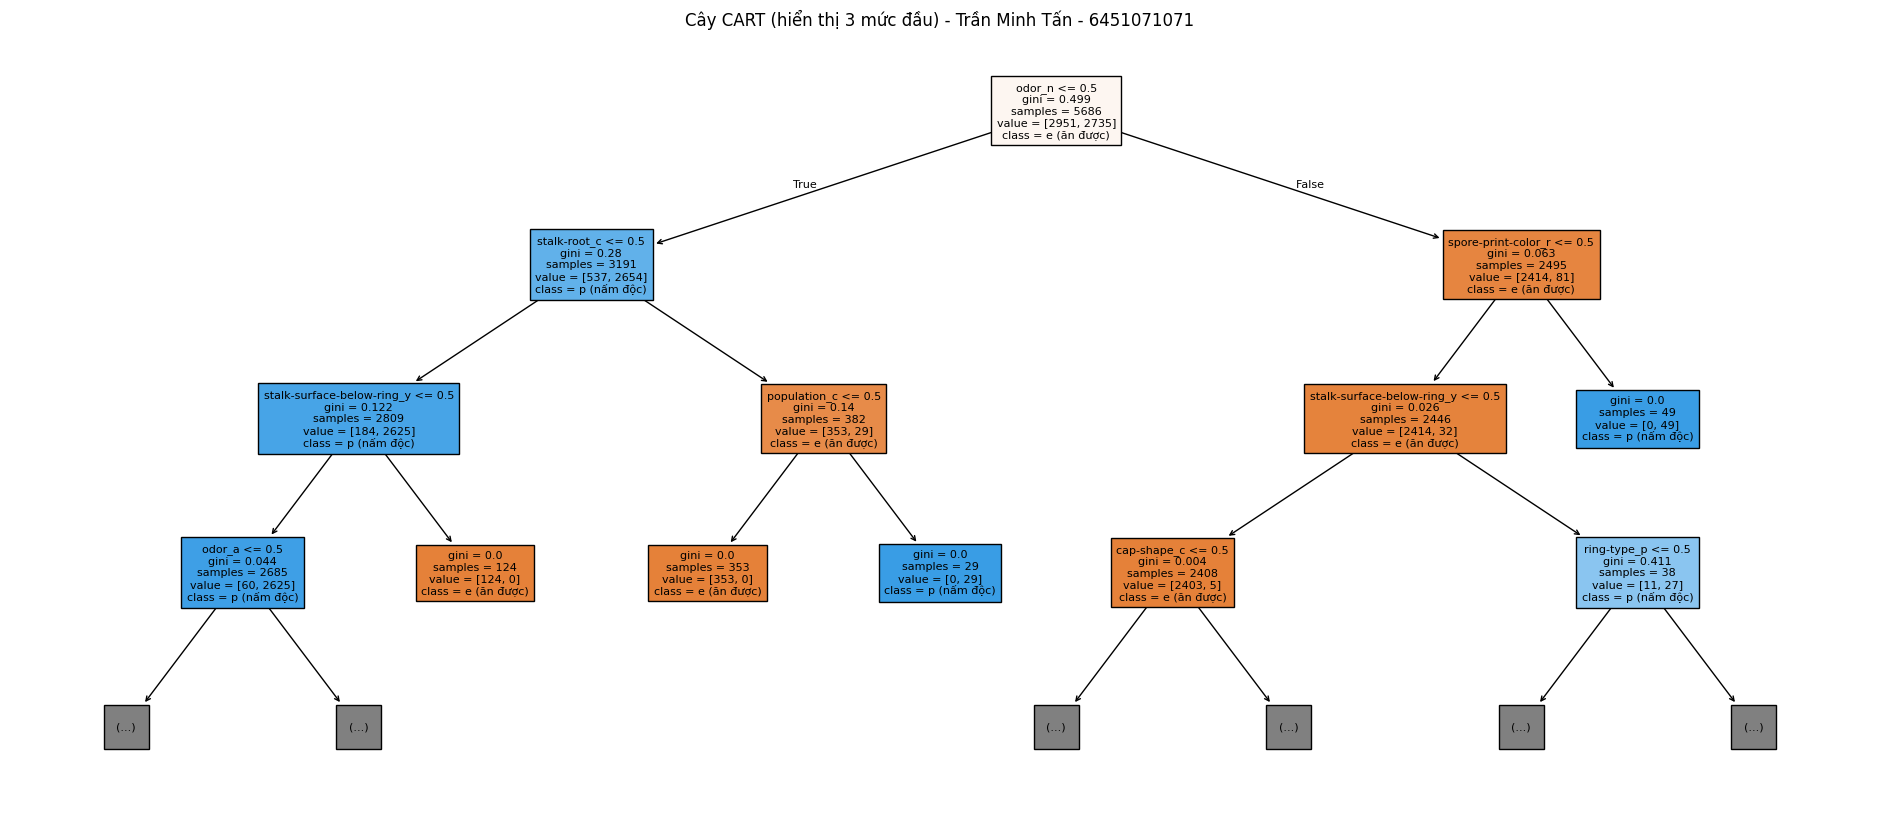

In [6]:
info("Câu 8 - Cây CART")

# CART dùng gini
cart = DecisionTreeClassifier(criterion="gini", random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Accuracy CART:", round(accuracy_score(y_test, pred_cart), 4))
print("Độ sâu cây:", cart.get_depth(), "| Số lá:", cart.get_n_leaves())
print(classification_report(y_test, pred_cart, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_cart, labels=["e","p"], cmap="Greens", ax=ax)
ax.set_title(f"Confusion matrix - CART\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(24,10))
plot_tree(cart, feature_names=X_train.columns, class_names=["e (ăn được)", "p (nấm độc)"],
          filled=True, fontsize=8, max_depth=3)
plt.title(f"Cây CART (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 7: Câu 9 - Naive Bayes

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 9 - Naive Bayes
Accuracy Naive Bayes: 0.9344
              precision    recall  f1-score   support

           e       0.90      0.99      0.94      1257
           p       0.98      0.88      0.93      1181

    accuracy                           0.93      2438
   macro avg       0.94      0.93      0.93      2438
weighted avg       0.94      0.93      0.93      2438



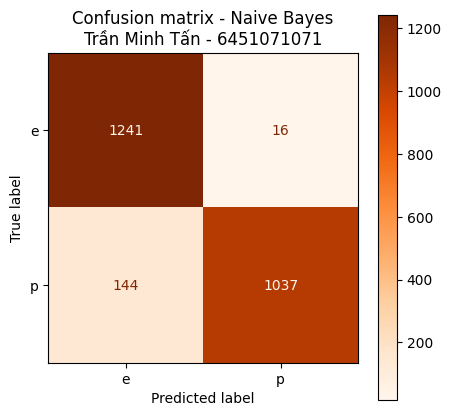

In [7]:
info("Câu 9 - Naive Bayes")

from sklearn.naive_bayes import BernoulliNB

# Dữ liệu one-hot (0/1) nên dùng Bernoulli Naive Bayes
nb = BernoulliNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Accuracy Naive Bayes:", round(accuracy_score(y_test, pred_nb), 4))
print(classification_report(y_test, pred_nb, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_nb, labels=["e","p"], cmap="Oranges", ax=ax)
ax.set_title(f"Confusion matrix - Naive Bayes\n{HO_TEN} - {MSSV}")
plt.show()

## Cell 8: Câu 10 - So sánh kết quả các mô hình

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 10 - So sánh kết quả các mô hình


,Accuracy,Precision,Recall,F1-score
Mô hình,,,,
ID3,1.0000,1.0000,1.0000,1.0000
CART,1.0000,1.0000,1.0000,1.0000
Naive Bayes,0.9344,0.9848,0.8781,0.9284


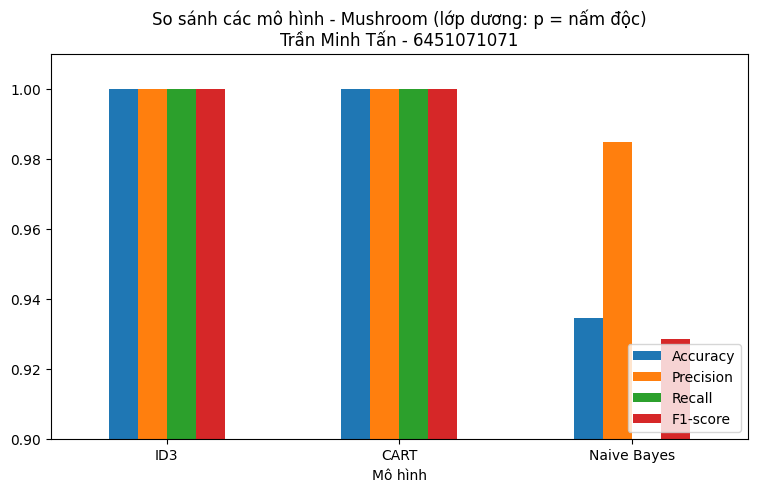

Mô hình có Accuracy cao nhất: ID3 (1.0)


In [8]:
info("Câu 10 - So sánh kết quả các mô hình")

results = []
for name, pred in [("ID3", pred_id3), ("CART", pred_cart), ("Naive Bayes", pred_nb)]:
    results.append({
        "Mô hình":   name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label="p", zero_division=0),
        "Recall":    recall_score(y_test, pred, pos_label="p", zero_division=0),
        "F1-score":  f1_score(y_test, pred, pos_label="p", zero_division=0),
    })

res = pd.DataFrame(results).set_index("Mô hình").round(4)
display(res)

res.plot(kind="bar", figsize=(9,5), ylim=(0.9,1.01))
plt.title(f"So sánh các mô hình - Mushroom (lớp dương: p = nấm độc)\n{HO_TEN} - {MSSV}")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best = res["Accuracy"].idxmax()
print(f"Mô hình có Accuracy cao nhất: {best} ({res.loc[best,'Accuracy']})")